# 01 · Le filtre passe-bas

**But :** comprendre et programmer un filtre qui **garde les sons graves** et **atténue les aigus**, puis s'en servir pour monter le volume des graves.

1. Les notions de base
2. Préparation
3. Un signal de test
4. Filtre n° 1 : la moyenne mobile
5. Filtre n° 2 : le lissage exponentiel
6. Comparer avant / après
7. Monter le volume des graves
8. À retenir

Exécutez les cellules dans l'ordre (**Exécuter tout**).

## 1. Les notions de base

**Le signal.** Un son est une vibration de l'air. Un micro la transforme en **signal** : une valeur qui monte et descend au cours du temps.

**L'échantillon.** Un ordinateur ne peut pas stocker une courbe continue. Il **mesure** le signal à intervalles réguliers. Chaque mesure est un **échantillon**, un nombre entre −1 et +1. Le nombre de mesures par seconde est la **fréquence d'échantillonnage** $f_s$. Ici, $f_s$ = 44 100 : 44 100 échantillons par seconde.

**La sinusoïde.** C'est le son le plus simple, une oscillation régulière : $x(t) = A \sin(2\pi f t)$.
- $f$ est la **fréquence** : le nombre d'oscillations par seconde, en hertz (Hz). Lent = **grave**, rapide = **aigu**.
- $A$ est l'**amplitude** : la hauteur de l'oscillation. Plus elle est grande, plus le son est fort.

**Cellule suivante :** dessine un son grave et un son aigu, puis un zoom qui montre les échantillons.

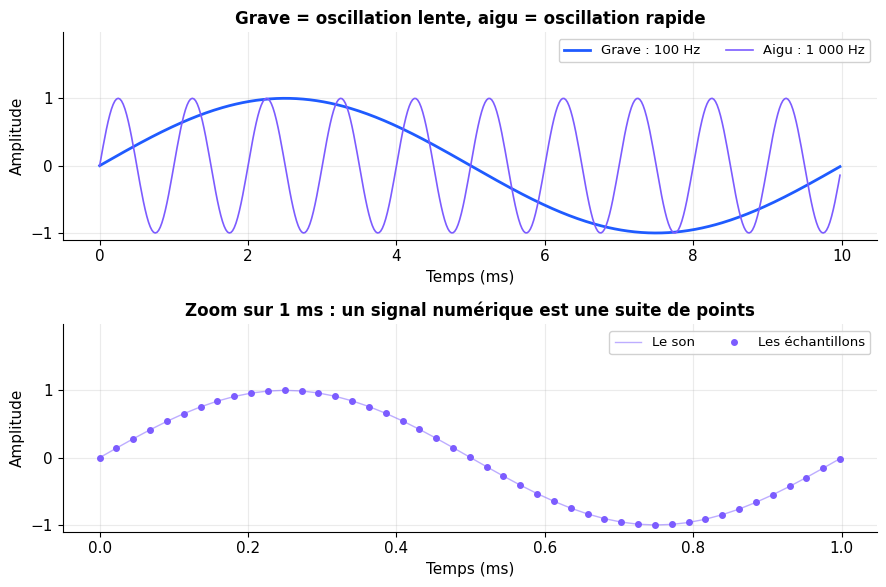

In [1]:
%matplotlib inline
import numpy as np
from outils import *          # mesures, graphiques et écoute (voir outils.py, inutile de le lire)

figure_echantillons()

**Le spectre.** Tout son, même compliqué, est une **somme de sinusoïdes**. Le **spectre** indique quelles fréquences sont présentes et avec quelle force. On le calcule avec la **FFT** (transformée de Fourier rapide).

**Le décibel (dB).** Pour comparer deux amplitudes, on utilise les décibels : $G_{dB} = 20 \log_{10}(\text{rapport})$.

| Amplitude multipliée par | ×2 | ×1 | ×0,707 | ×0,5 | ×0,1 | ×0,01 |
|---|---|---|---|---|---|---|
| Gain en dB | +6 | 0 | −3 | −6 | −20 | −40 |

**Le filtre.** Un filtre est un calcul qui change l'amplitude de chaque fréquence. Un **passe-bas** laisse passer les graves et atténue les aigus.

**La fréquence de coupure $f_c$.** C'est la frontière du filtre. Par convention, c'est la fréquence qu'il ne laisse passer qu'à 70,7 % (−3 dB). Ici, $f_c$ = 250 Hz : la frontière graves / médiums d'EGALIZE.

## 2. Préparation

**Cellule suivante :** fixe les deux réglages de l'étude.

In [2]:
FC = 250.0      # fréquence de coupure visée (Hz)
DUREE = 2.0     # durée du signal de test (s)

## 3. Un signal de test

On fabrique un signal **dont on connaît tout** : trois sinusoïdes additionnées, une par bande de l'égaliseur.

| Note | Fréquence | Amplitude |
|---|---|---|
| grave | 100 Hz | 0,30 |
| médium | 1 000 Hz | 0,20 |
| aiguë | 5 000 Hz | 0,12 |

Après filtrage, on pourra mesurer exactement ce qu'est devenue chaque note.

**Cellule suivante :** crée le temps, les trois notes et leur somme `x`.

In [3]:
t = np.arange(int(DUREE * FS)) / FS        # les instants de mesure : 0, 1/FS, 2/FS, …

NOTES = {                                  # nom : (fréquence en Hz, amplitude)
    "Grave 100 Hz": (100, 0.30),
    "Médium 1 kHz": (1000, 0.20),
    "Aiguë 5 kHz": (5000, 0.12),
}
sinusoides = {nom: A * np.sin(2 * np.pi * f * t) for nom, (f, A) in NOTES.items()}   # A·sin(2πft)
x = sum(sinusoides.values())               # le signal de test = la somme des trois notes

print(len(x), "échantillons")

88200 échantillons


**Cellule suivante :** affiche le signal (dans le temps et en spectre) et propose de l'écouter.

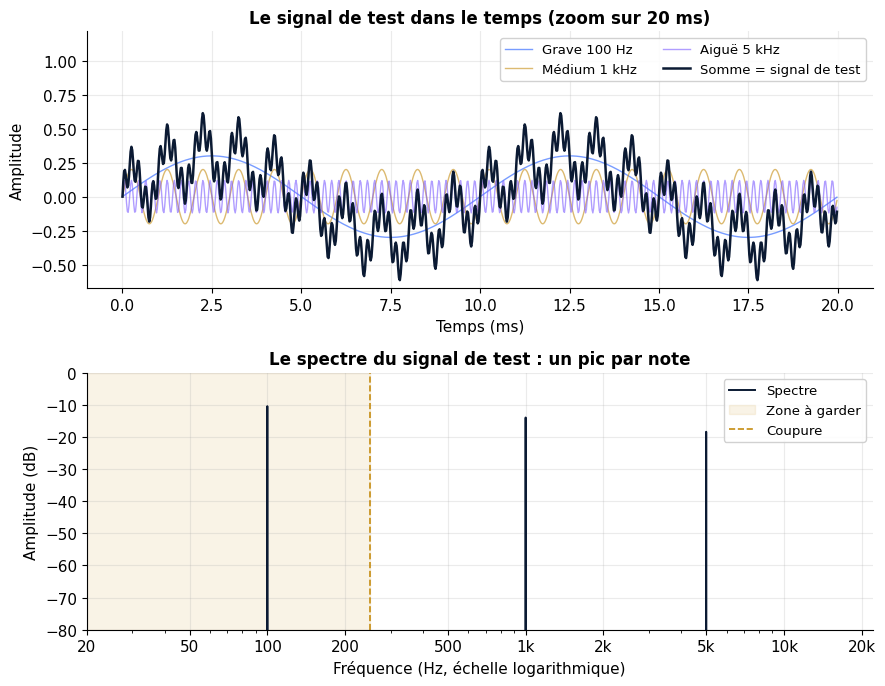

Signal de test — crête : 0.61


In [4]:
tracer_signal(t, sinusoides, x, coupures=[FC], zone=(20, FC))
ecouter(x, "Signal de test")

**À observer :**

- En haut : la grande ondulation lente est la grave. Les petites oscillations rapides posées dessus sont la médium et l'aiguë.
- En bas : chaque note donne un **pic** à sa fréquence. Seul le pic de 100 Hz est dans la zone à garder.

## 4. Filtre n° 1 : la moyenne mobile

**Idée :** remplacer chaque échantillon par la **moyenne des M derniers**.

| Signal | Échantillons | Moyenne de 2 voisins |
|---|---|---|
| lent (grave) | 5, 5, 5, 5 | 5, 5, 5 : **intact** |
| rapide (aigu) | +1, −1, +1, −1 | 0, 0, 0 : **effacé** |

Une variation lente survit à la moyenne. Une variation rapide s'annule.

$$y[n] = \frac{x[n] + x[n-1] + \dots + x[n-M+1]}{M}$$

($x$ = entrée, $y$ = sortie, $n$ = numéro de l'échantillon.)

**Choisir M :** plus la fenêtre est longue, plus on coupe bas. Pour la moyenne mobile, $f_c \approx 0{,}443 \times f_s / M$, donc $M \approx 0{,}443 \times f_s / f_c$.

**Cellule suivante :** programme le filtre et calcule M. Pour vérifier la coupure, elle envoie une sinusoïde de 250 Hz dans le filtre : celle-ci doit ressortir à environ 70 % (−3 dB). Enfin, elle filtre le signal de test.

In [5]:
def moyenne_mobile(x, M):
    y = np.zeros(len(x))
    somme = 0.0
    for n in range(len(x)):
        somme = somme + x[n]              # l'échantillon n entre dans la fenêtre…
        if n >= M:
            somme = somme - x[n - M]      # … et l'échantillon n − M en sort
        y[n] = somme / M                  # moyenne des M échantillons de la fenêtre
    return y


M = round(0.443 * FS / FC)
print("M =", M, "échantillons")

gain = gain_a(lambda s: moyenne_mobile(s, M), FC)
print(f"Une sinusoïde de {FC:.0f} Hz ressort à {gain:.0%} ({en_db(gain):.1f} dB)")

y_mm = moyenne_mobile(x, M)

M = 78 échantillons
Une sinusoïde de 250 Hz ressort à 71% (-3.0 dB)


**À observer :**

une fenêtre de 78 échantillons (moins de 2 millisecondes) suffit pour couper à 250 Hz.

## 5. Filtre n° 2 : le lissage exponentiel

**Idée :** la sortie **suit l'entrée avec retard**, comme un thermomètre qui met du temps à monter. À chaque échantillon, elle rattrape une petite fraction α de son retard.

$$y[n] = y[n-1] + \alpha \times \big(x[n] - y[n-1]\big)$$

- α petit : la sortie suit lentement, elle ne garde que les graves.
- α proche de 1 : la sortie suit presque tout.

Lien entre α et la coupure : $\alpha = 1 - e^{-2\pi f_c / f_s}$

**Cellule suivante :** programme le filtre, calcule α, vérifie la coupure à 250 Hz, puis filtre le signal de test.

In [6]:
def lissage_exponentiel(x, alpha):
    y = np.zeros(len(x))
    precedent = 0.0                                  # la sortie précédente y[n−1] (0 au départ)
    for n in range(len(x)):
        retard = x[n] - precedent                    # de combien la sortie est en retard
        precedent = precedent + alpha * retard       # on rattrape une fraction alpha de ce retard
        y[n] = precedent
    return y


alpha = 1 - np.exp(-2 * np.pi * FC / FS)
print(f"alpha = {alpha:.3f}")

gain = gain_a(lambda s: lissage_exponentiel(s, alpha), FC)
print(f"Une sinusoïde de {FC:.0f} Hz ressort à {gain:.0%} ({en_db(gain):.1f} dB)")

y_exp = lissage_exponentiel(x, alpha)

alpha = 0.035
Une sinusoïde de 250 Hz ressort à 71% (-3.0 dB)


**À observer :**

α ≈ 0,035 : à chaque échantillon, la sortie ne rattrape que 3,5 % de son retard. Elle est trop lente pour suivre la médium et l'aiguë.

## 6. Comparer avant / après

### Dans le temps

**Cellule suivante :** superpose le signal d'origine, la grave seule (l'objectif) et les sorties des deux filtres, sur 20 ms.

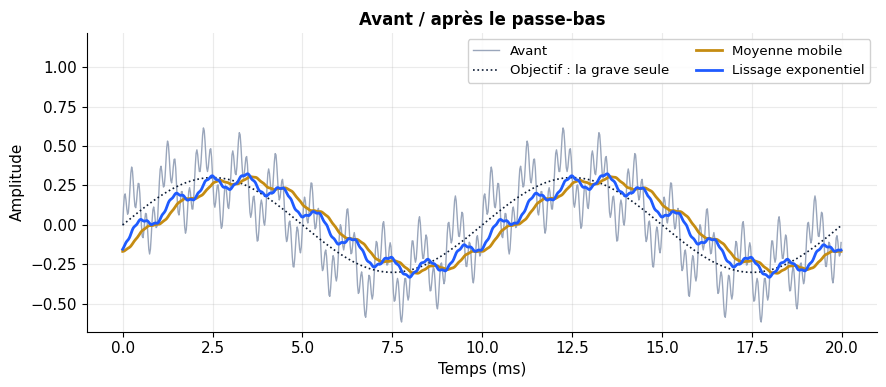

In [7]:
tracer_avant_apres(t, x, sinusoides["Grave 100 Hz"], "la grave seule",
                   [(y_mm, OR, "Moyenne mobile"), (y_exp, BLEU, "Lissage exponentiel")],
                   duree_ms=20, titre="Avant / après le passe-bas")

**À observer :**

- Les deux sorties sont lisses et suivent la grave : les oscillations rapides ont presque disparu.
- Elles sont **légèrement en retard** sur la grave. C'est normal : pour faire une moyenne, il faut attendre les échantillons.

### Dans les fréquences

**Cellule suivante :** compare les spectres et donne, pour chaque note, la variation en dB.

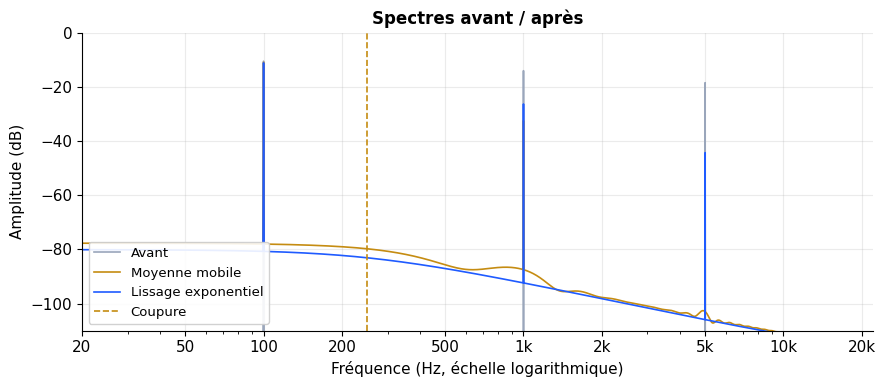

,Moyenne mobile,Lissage exponentiel
Note,,
Grave 100 Hz,-0.5 dB,-0.6 dB
Médium 1 kHz,-18.5 dB,-12.3 dB
Aiguë 5 kHz,-35.2 dB,-25.8 dB


In [8]:
sorties = [(y_mm, OR, "Moyenne mobile"), (y_exp, BLEU, "Lissage exponentiel")]
tracer_spectres(x, sorties, NOTES, coupures=[FC])
tableau_notes(x, sorties, NOTES)

**À observer :**

- La grave ne perd presque rien (environ −0,5 dB).
- La médium et l'aiguë baissent fortement, mais **ne disparaissent pas** : la médium perd 12 à 18 dB, et on l'entend encore.

### La réponse en fréquence

On envoie dans le filtre des sinusoïdes pures, de 30 Hz à 20 kHz, une par une, et on mesure ce qui ressort. La courbe obtenue est la **carte d'identité** du filtre.

**Cellule suivante :** mesure la réponse des deux filtres et les compare au filtre idéal, qui couperait net à 250 Hz.

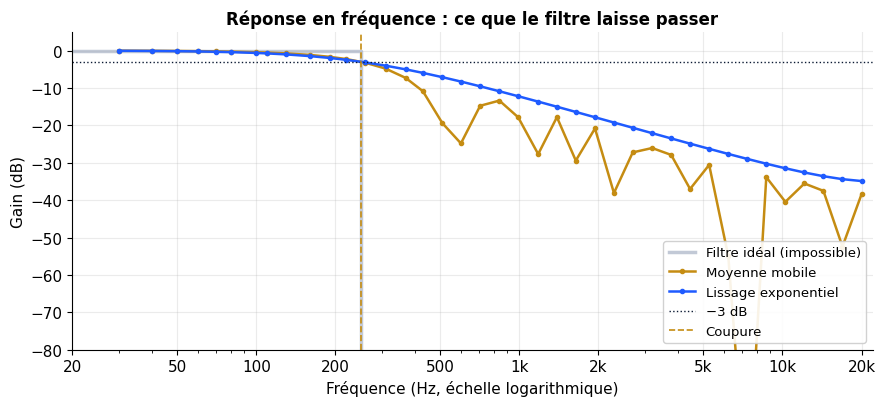

In [9]:
f_mm, g_mm = reponse_mesuree(lambda s: moyenne_mobile(s, M))
f_exp, g_exp = reponse_mesuree(lambda s: lissage_exponentiel(s, alpha))
tracer_reponses([(f_mm, g_mm, OR, "Moyenne mobile"), (f_exp, g_exp, BLEU, "Lissage exponentiel")],
                coupures=[FC], ideal=([20, FC, FC], [0, 0, -80]))

**À observer :**

- Les deux courbes passent par −3 dB à 250 Hz : la coupure est au bon endroit.
- **Lissage exponentiel :** la courbe descend régulièrement. Chaque fois que la fréquence double, l'amplitude est divisée par 2 (−6 dB par octave).
- **Moyenne mobile :** la courbe descend plus vite, mais elle **rebondit**.
- Aucun des deux ne coupe net comme le filtre idéal : la transition est progressive. Un filtre idéal est impossible à réaliser.

### À l'écoute

**Cellule suivante :** affiche l'original et les deux versions filtrées.

In [10]:
ecouter(x, "Avant")
ecouter(y_mm, "Moyenne mobile")
ecouter(y_exp, "Lissage exponentiel")

Avant — crête : 0.61


Moyenne mobile — crête : 0.31


Lissage exponentiel — crête : 0.33


**À observer :**

après filtrage, le son est **étouffé** : la note grave domine.

## 7. Monter le volume des graves

C'est le travail d'un égaliseur :

1. **isoler** les graves : `graves = passe_bas(x)` ;
2. garder **le reste** : `reste = x − graves` ;
3. **amplifier** les graves, puis **recombiner** : `x_eq = reste + facteur × graves`.

Le gain se donne en dB et se convertit en facteur : $\text{facteur} = 10^{G/20}$. Par exemple, +6 dB ≈ ×2.

**Cellule suivante :** monte les graves de 6 dB. Elle vérifie qu'avec un gain de 0 dB on retrouve exactement le signal d'origine, et que le signal ne dépasse pas ±1 (sinon il serait **écrêté**, c'est-à-dire coupé et distordu).

In [11]:
G_DB = 6.0                                   # gain voulu sur les graves (essayez −6, +3, +12)
facteur = 10 ** (G_DB / 20)

graves = lissage_exponentiel(x, alpha)       # 1. isoler les graves
reste = x - graves                           # 2. le reste
x_eq = reste + facteur * graves              # 3. amplifier puis recombiner

print("À 0 dB, on retrouve x :", np.allclose(reste + graves, x))
print(f"Crête : {np.max(np.abs(x)):.2f} avant, {np.max(np.abs(x_eq)):.2f} après")

À 0 dB, on retrouve x : True
Crête : 0.61 avant, 0.91 après


**Cellule suivante :** montre la séparation, le signal avant / après et les spectres.

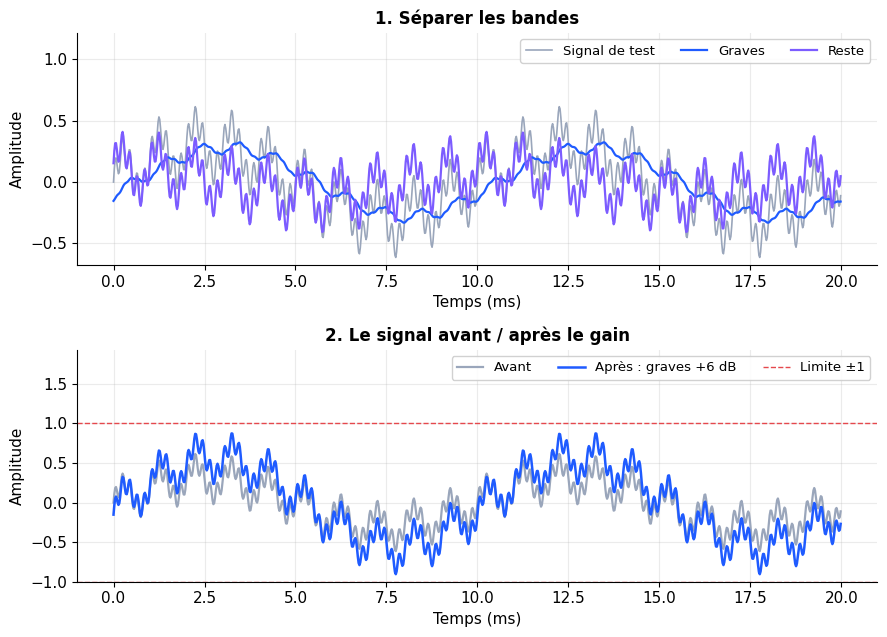

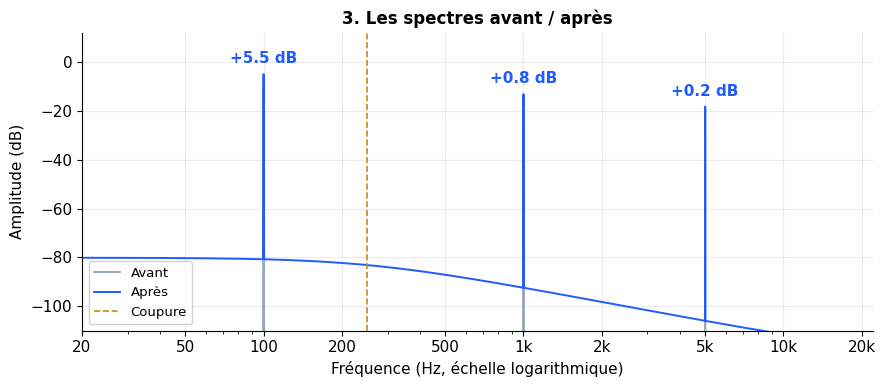

In [12]:
tracer_egalisation(t, x, x_eq, [(graves, BLEU, "Graves"), (reste, VIOLET, "Reste")],
                   NOTES, coupures=[FC], titre_apres=f"graves {G_DB:+.0f} dB")

**Cellule suivante :** compare le gain voulu et le gain obtenu, puis propose l'écoute.

In [13]:
display(tableau_gains(x, x_eq, NOTES, {"Grave 100 Hz": G_DB, "Médium 1 kHz": 0, "Aiguë 5 kHz": 0}))
ecouter(x, "Avant")
ecouter(x_eq, f"Graves {G_DB:+.0f} dB")

,Gain voulu,Gain obtenu
Note,,
Grave 100 Hz,+6.0 dB,+5.5 dB
Médium 1 kHz,+0.0 dB,+0.8 dB
Aiguë 5 kHz,+0.0 dB,+0.2 dB


Avant — crête : 0.61


Graves +6 dB — crête : 0.91


**À observer :**

- La grave gagne un peu moins que 6 dB : le filtre ne la garde pas à 100 % et la décale légèrement dans le temps.
- La médium monte un peu alors qu'on ne l'a pas demandé : le filtre en laisse passer une partie dans les « graves », et cette partie reçoit le gain.
- Pour réduire ces défauts, il faudra des filtres qui coupent plus net.

## 8. À retenir

- Un **passe-bas** garde les graves et atténue les aigus. Son principe est de **faire une moyenne**.
- **Moyenne mobile :** moyenne des M derniers échantillons. **Lissage exponentiel :** la sortie rattrape une fraction α de son retard.
- La **fréquence de coupure** est l'endroit où le filtre ne laisse passer que 70,7 % (−3 dB).
- Un vrai filtre **ne coupe jamais net** : la transition est progressive, et il **retarde** un peu le signal.
- **Égaliser** = isoler une bande, la multiplier par $10^{G/20}$, puis tout additionner.

**Essayez :** passez `FC` à 1000, ou `G_DB` à −6 ou à 12, puis relancez tout (**Exécuter tout**).